Loading libraries

In [1]:
import pandas as pd

city = pd.read_csv("../delhi-aqi-prediction-using-ml/data/city_hour.csv")
delhi_ncr = pd.read_csv("../delhi-aqi-prediction-using-ml/data/delhi_ncr_aqi_dataset.csv")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12208\2157271278.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
city.rename(columns={"Datetime": "datetime"}, inplace=True)

In [3]:
city["datetime"] = pd.to_datetime(city["datetime"])
delhi_ncr["datetime"] = pd.to_datetime(delhi_ncr["datetime"])


Filtering ONLY Delhi from city_hour

In [4]:
city_delhi = city[city["City"] == "Delhi"]

In [5]:
print(city_delhi.columns)
print(delhi_ncr.columns)

city_delhi.columns = city_delhi.columns.str.lower().str.replace(".", "").str.replace("_", "")
delhi_ncr.columns = delhi_ncr.columns.str.lower().str.replace(".", "").str.replace("_", "")

Index(['City', 'datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO',
       'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='object')
Index(['datetime', 'date', 'year', 'month', 'day', 'hour', 'day_of_week',
       'is_weekend', 'season', 'city', 'station', 'latitude', 'longitude',
       'pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'temperature', 'humidity',
       'wind_speed', 'visibility', 'aqi', 'aqi_category'],
      dtype='object')


In [6]:
print(city_delhi.columns)
print(delhi_ncr.columns)

delhi_ncr.rename(columns={"aqicategory": "aqibucket"}, inplace=True)
common_cols = list(set(city_delhi.columns) & set(delhi_ncr.columns))
combined = pd.concat([city_delhi, delhi_ncr])
combined = combined.sort_values(by="datetime")
combined.reset_index(drop=True, inplace=True)
combined = combined.dropna(subset=["aqi"])

print(combined["datetime"].min())
print(combined["datetime"].max())

combined = combined.fillna(method="ffill")


Index(['city', 'datetime', 'pm25', 'pm10', 'no', 'no2', 'nox', 'nh3', 'co',
       'so2', 'o3', 'benzene', 'toluene', 'xylene', 'aqi', 'aqibucket'],
      dtype='object')
Index(['datetime', 'date', 'year', 'month', 'day', 'hour', 'dayofweek',
       'isweekend', 'season', 'city', 'station', 'latitude', 'longitude',
       'pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'temperature', 'humidity',
       'windspeed', 'visibility', 'aqi', 'aqicategory'],
      dtype='object')
2015-01-01 16:00:00
2025-12-31 23:00:00


C:\Users\ASUS\AppData\Local\Temp\ipykernel_12208\2951190737.py:14: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  combined = combined.fillna(method="ffill")


In [7]:
city.columns = city.columns.str.lower()
delhi_ncr.columns = delhi_ncr.columns.str.lower()

common_cols = list(set(city_delhi.columns) & set(delhi_ncr.columns))
city_delhi = city_delhi[common_cols]
delhi_ncr = delhi_ncr[common_cols]

In [8]:
combined = pd.concat([city_delhi, delhi_ncr])
combined = combined.sort_values(by="datetime")
combined.reset_index(drop=True, inplace=True)

In [9]:
print(combined.head())
print(combined.tail())

     no2            datetime aqibucket     co    pm10     o3   city  aqi  \
0  41.78 2015-01-01 01:00:00       NaN   9.29  935.18  54.94  Delhi  NaN   
1  43.46 2015-01-01 02:00:00       NaN  13.28     NaN  50.53  Delhi  NaN   
2  41.19 2015-01-01 03:00:00       NaN  29.67     NaN  19.33  Delhi  NaN   
3  39.55 2015-01-01 04:00:00       NaN  21.76     NaN  20.08  Delhi  NaN   
4  37.41 2015-01-01 05:00:00       NaN  26.19  976.99  16.00  Delhi  NaN   

     pm25   so2  
0  454.58  3.41  
1  440.44  3.88  
2  409.09  2.83  
3  436.12  4.33  
4  415.88  6.17  
          no2            datetime aqibucket    co   pm10    o3       city  \
249851   94.8 2025-12-31 23:00:00    Severe  3.73  522.4  27.7      Delhi   
249852  138.7 2025-12-31 23:00:00    Severe  5.17  600.4  14.8      Noida   
249853   93.0 2025-12-31 23:00:00    Severe  3.12  501.2  28.2      Noida   
249854  108.6 2025-12-31 23:00:00    Severe  4.65  632.3  15.6   Gurugram   
249855   89.0 2025-12-31 23:00:00    Severe  5.17 

Handle missing data

In [10]:
combined = combined.sort_values(by="datetime")

# forward fill (time-series best method)
combined.fillna(method="ffill", inplace=True)

# optional backward fill
combined.fillna(method="bfill", inplace=True)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12208\2415506660.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  combined.fillna(method="ffill", inplace=True)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_12208\2415506660.py:7: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  combined.fillna(method="bfill", inplace=True)


In [11]:
print(city_delhi["aqi"].head(20))
print(city_delhi["aqi"].isnull().sum())

245172      NaN
245173      NaN
245174      NaN
245175      NaN
245176      NaN
245177      NaN
245178      NaN
245179      NaN
245180      NaN
245181      NaN
245182      NaN
245183      NaN
245184      NaN
245185      NaN
245186      NaN
245187    456.0
245188    450.0
245189    446.0
245190    475.0
245191    480.0
Name: aqi, dtype: float64
498


Feature engineering

In [12]:
combined["hour"] = combined["datetime"].dt.hour
combined["day"] = combined["datetime"].dt.day
combined["month"] = combined["datetime"].dt.month
combined["dayofweek"] = combined["datetime"].dt.dayofweek

In [13]:
features = ["pm25", "pm10", "no2", "so2", "co", "o3", "hour", "month", "dayofweek"]

X = combined[features]
y = combined["aqi"]

In [14]:
split = int(0.8 * len(combined))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

In [15]:
print(combined.isnull().sum())

no2          0
datetime     0
aqibucket    0
co           0
pm10         0
o3           0
city         0
aqi          0
pm25         0
so2          0
hour         0
day          0
month        0
dayofweek    0
dtype: int64


Training models now

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

In [17]:
#linear regression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [18]:
#random forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [19]:
#svr
# scaler = StandardScaler()

# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# svr = SVR(kernel="rbf")
# svr.fit(X_train_scaled, y_train)

# y_pred_svr = svr.predict(X_test_scaled)

In [20]:
def evaluate(y_test, y_pred, name):
    print(f"{name} R2:", r2_score(y_test, y_pred))
    print(f"{name} RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
    print("------")

evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest")

Linear Regression R2: 0.6710984096479045
Linear Regression RMSE: 104.64113214227395
------
Random Forest R2: 0.9999620798410381
Random Forest RMSE: 1.123581339118065
------


In [21]:
#feature importance
import pandas as pd

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
}).sort_values(by="importance", ascending=False)

print(importance)

     feature  importance
0       pm25    0.765918
1       pm10    0.171982
2        no2    0.019123
4         co    0.015300
5         o3    0.007554
3        so2    0.007101
7      month    0.006238
6       hour    0.004587
8  dayofweek    0.002198


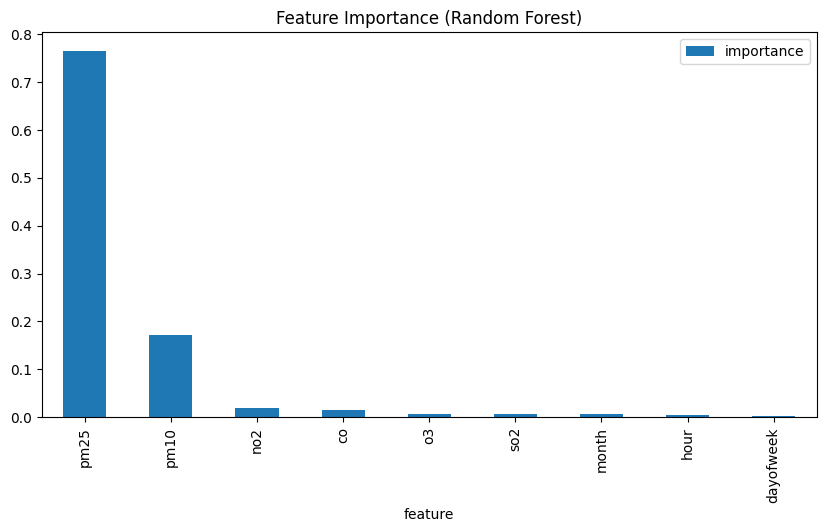

In [22]:
import matplotlib.pyplot as plt

importance.plot(kind="bar", x="feature", y="importance", figsize=(10,5))
plt.title("Feature Importance (Random Forest)")
plt.show()

In [23]:
combined.to_csv("final_aqi_dataset.csv", index=False)

Storing data properly

In [24]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd

results = []

def evaluate(y_test, y_pred, name):
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    results.append({
        "Model": name,
        "R2 Score": r2,
        "RMSE": rmse
    })

# Evaluate all models
evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest")


# Display results
results_df = pd.DataFrame(results)
print(results_df)

               Model  R2 Score        RMSE
0  Linear Regression  0.671098  104.641132
1      Random Forest  0.999962    1.123581


In [ ]:
#tuning random forest
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [ ]:
evaluate(y_test, y_pred_rf, "Tuned Random Forest")

Step by step ARIMA

In [ ]:
#creating time series features
ts = combined[["datetime", "aqi"]]

ts = ts.groupby("datetime").mean()   # remove duplicates

ts = ts.asfreq("h")                  # set hourly frequency
ts = ts.sort_index()

# fill missing values (important)
ts = ts.ffill()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_14040\836978240.py:10: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  ts = ts.fillna(method="ffill")


In [ ]:
#check stationarity
from statsmodels.tsa.stattools import adfuller

result = adfuller(ts["aqi"])
print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -6.212438635106519
p-value: 5.466313070252046e-08


In [ ]:
train_size = int(0.8 * len(ts))

train = ts["aqi"].iloc[:train_size]
test = ts["aqi"].iloc[train_size:]

In [ ]:
model = ARIMA(train, order=(2,0,2))
model_fit = model.fit()

In [ ]:
#forecast
forecast = model_fit.predict(
    start=test.index[0],
    end=test.index[-1]
)
rmse = np.sqrt(mean_squared_error(test.values, forecast.values))
print("ARIMA RMSE:", rmse)

ARIMA RMSE: 173.24240754138265


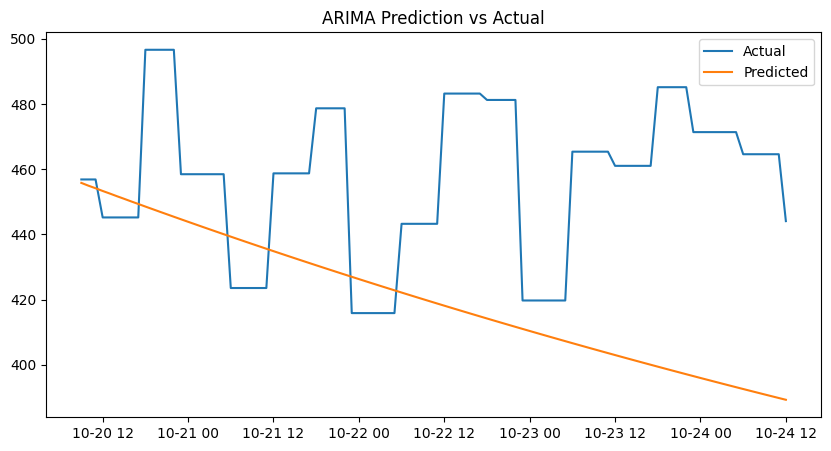

In [ ]:
#visualize
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(test[:100], label="Actual")
plt.plot(forecast[:100], label="Predicted")

plt.legend()
plt.title("ARIMA Prediction vs Actual")
plt.show()

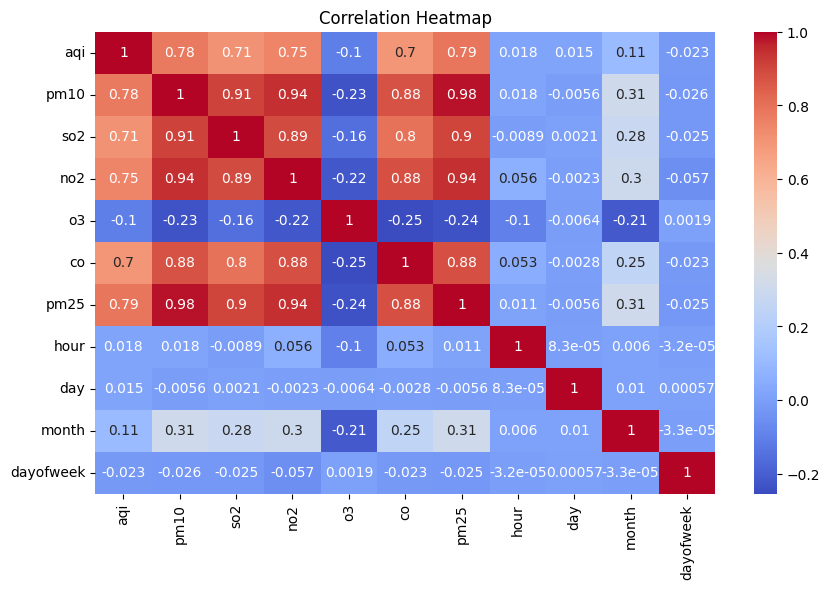

In [ ]:
correlation = combined.select_dtypes(include=['number']).corr()
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
y_pred_baseline = y_test.shift(1)
rmse_baseline = np.sqrt(mean_squared_error(y_test[1:], y_pred_baseline[1:]))

print("Baseline RMSE:", rmse_baseline)

Baseline RMSE: 42.26234969327813


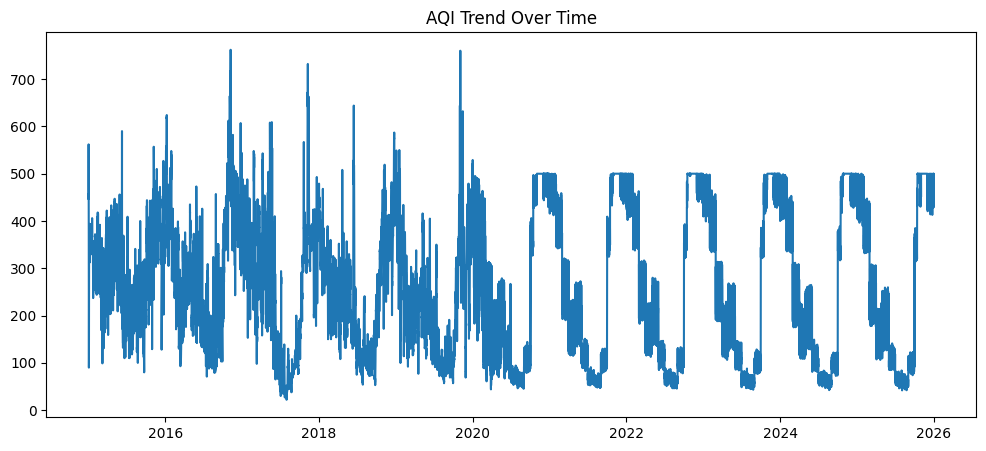

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(ts["aqi"])
plt.title("AQI Trend Over Time")
plt.show()

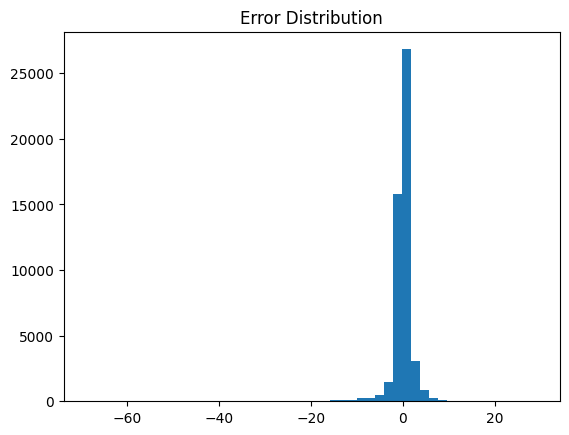

In [ ]:
errors = y_test - y_pred_rf

plt.hist(errors, bins=50)
plt.title("Error Distribution")
plt.show()

In [ ]:
Cross validation

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestRegressor

tscv = TimeSeriesSplit(n_splits=5)

rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X, y, cv=tscv, scoring="r2")

print("Cross-val R2 scores:", scores)
print("Average R2:", scores.mean())

Cross-val R2 scores: [0.86798631 0.99972171 0.99990909 0.99994476 0.99995889]
Average R2: 0.9735041515359668


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)   

RandomForestRegressor(random_state=42)

In [ ]:
#train vs test performance
print("Train R2:", r2_score(y_train, rf.predict(X_train)))
print("Test R2:", r2_score(y_test, y_pred_rf))

Train R2: 0.9970334547941807
Test R2: 0.9998435553612146


In [ ]:
import joblib

joblib.dump(rf, "aqi_model.pkl")

['aqi_model.pkl']